# **E-commerce Customer & Order Analysis**

## 1. Introduction

E-commerce has become an important part of the modern retail industry. Understanding customer behaviour, sales performance and order delivery is essential for businesses to improve their services and make better decisions.

In this project, I will analyse the Brazilian E-Commerce Public Dataset by Olist. The dataset contains information about customers, orders, products, payments, sellers and customer reviews.

Using Python, Pandas and SQL, I will explore the data, identify patterns and investigate different aspects of e-commerce business performance.

## 2. Project Objectives

- Analyse overall sales and order performance.
- Understand customer purchasing behaviour.
- Identify popular product categories.
- Examine order delivery performance.
- Explore customer reviews and satisfaction.
- Practise SQL queries on multiple related datasets.
- Extract meaningful insights and provide business recommendations.

## 3. Tools and Technologies

- Python
- Pandas
- NumPy
- SQL
- Matplotlib
- Seaborn
- Google Colab

## 4. Key Business Questions

1. Which product categories generate the highest product sales?
2. How many customers make repeat purchases?
3. How long does delivery usually take?
4. How do sales change over time?

## 5. Dataset

The project uses the Brazilian E-Commerce Public Dataset by Olist, obtained from Kaggle. It consists of multiple CSV files containing information about different aspects of the e-commerce business.

## 1) Setting Up the Environment

In [1]:
# Import drive from Google Colab to access files stored in Google Drive
from google.colab import drive

# Import os to work with folders and file paths
import os

# Mount Google Drive so we can access our dataset
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## 2) Locating the Dataset

In [3]:
# Define the path to our Olist dataset folder in Google Drive
data_path = '/content/drive/MyDrive/archive (1)'

# Display all files inside the dataset folder
os.listdir(data_path)

['olist_customers_dataset.csv',
 'olist_geolocation_dataset.csv',
 'olist_order_items_dataset.csv',
 'olist_order_payments_dataset.csv',
 'olist_order_reviews_dataset.csv',
 'olist_orders_dataset.csv',
 'olist_products_dataset.csv',
 'olist_sellers_dataset.csv',
 'product_category_name_translation.csv']

## 3) Understanding the Datasets

The dataset contains nine CSV files. Before beginning the analysis, I will examine these files to understand the information they contain, their structure and how they are related to one another.

## 4) Importing Libraries

In [4]:
# Import pandas for loading and analysing the datasets
import pandas as pd

## 5) Loading the Datasets

In [5]:
# Load the CSV files into separate DataFrames
customers = pd.read_csv(data_path + '/olist_customers_dataset.csv')
geolocation = pd.read_csv(data_path + '/olist_geolocation_dataset.csv')
order_items = pd.read_csv(data_path + '/olist_order_items_dataset.csv')
order_payments = pd.read_csv(data_path + '/olist_order_payments_dataset.csv')
order_reviews = pd.read_csv(data_path + '/olist_order_reviews_dataset.csv')
orders = pd.read_csv(data_path + '/olist_orders_dataset.csv')
products = pd.read_csv(data_path + '/olist_products_dataset.csv')
sellers = pd.read_csv(data_path + '/olist_sellers_dataset.csv')
category_translation = pd.read_csv(data_path + '/product_category_name_translation.csv')

## 6) Initial Data Inspection

In [6]:
# Display the number of rows and columns in each dataset
datasets = {
    'Customers': customers,
    'Geolocation': geolocation,
    'Order Items': order_items,
    'Order Payments': order_payments,
    'Order Reviews': order_reviews,
    'Orders': orders,
    'Products': products,
    'Sellers': sellers,
    'Category Translation': category_translation
}

for name, df in datasets.items():
    print(name, df.shape)

Customers (99441, 5)
Geolocation (1000163, 5)
Order Items (112650, 7)
Order Payments (103886, 5)
Order Reviews (99224, 7)
Orders (99441, 8)
Products (32951, 9)
Sellers (3095, 4)
Category Translation (71, 2)


In [7]:
# Display the column names of each dataset
for name, df in datasets.items():
    print(f"\n{name}:")
    print(df.columns.tolist())


Customers:
['customer_id', 'customer_unique_id', 'customer_zip_code_prefix', 'customer_city', 'customer_state']

Geolocation:
['geolocation_zip_code_prefix', 'geolocation_lat', 'geolocation_lng', 'geolocation_city', 'geolocation_state']

Order Items:
['order_id', 'order_item_id', 'product_id', 'seller_id', 'shipping_limit_date', 'price', 'freight_value']

Order Payments:
['order_id', 'payment_sequential', 'payment_type', 'payment_installments', 'payment_value']

Order Reviews:
['review_id', 'order_id', 'review_score', 'review_comment_title', 'review_comment_message', 'review_creation_date', 'review_answer_timestamp']

Orders:
['order_id', 'customer_id', 'order_status', 'order_purchase_timestamp', 'order_approved_at', 'order_delivered_carrier_date', 'order_delivered_customer_date', 'order_estimated_delivery_date']

Products:
['product_id', 'product_category_name', 'product_name_lenght', 'product_description_lenght', 'product_photos_qty', 'product_weight_g', 'product_length_cm', 'produc

In [8]:
# Display the first five rows of each dataset
for name, df in datasets.items():
    print(f"\n{name}")
    display(df.head())


Customers


,customer_id,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state
0,06b8999e2fba1a1fbc88172c00ba8bc7,861eff4711a542e4b93843c6dd7febb0,14409,franca,SP
1,18955e83d337fd6b2def6b18a428ac77,290c77bc529b7ac935b93aa66c333dc3,9790,sao bernardo do campo,SP
2,4e7b3e00288586ebd08712fdd0374a03,060e732b5b29e8181a18229c7b0b2b5e,1151,sao paulo,SP
3,b2b6027bc5c5109e529d4dc6358b12c3,259dac757896d24d7702b9acbbff3f3c,8775,mogi das cruzes,SP
4,4f2d8ab171c80ec8364f7c12e35b23ad,345ecd01c38d18a9036ed96c73b8d066,13056,campinas,SP



Geolocation


,geolocation_zip_code_prefix,geolocation_lat,geolocation_lng,geolocation_city,geolocation_state
0,1037,-23.545621,-46.639292,sao paulo,SP
1,1046,-23.546081,-46.644820,sao paulo,SP
2,1046,-23.546129,-46.642951,sao paulo,SP
3,1041,-23.544392,-46.639499,sao paulo,SP
4,1035,-23.541578,-46.641607,sao paulo,SP



Order Items


,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.90,13.29
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.90,19.93
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.00,17.87
3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,2018-08-15 10:10:18,12.99,12.79
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,2017-02-13 13:57:51,199.90,18.14


... (8 outputs left out)


Sellers


,seller_id,seller_zip_code_prefix,seller_city,seller_state
0,3442f8959a84dea7ee197c632cb2df15,13023,campinas,SP
1,d1b65fc7debc3361ea86b5f14c68d2e2,13844,mogi guacu,SP
2,ce3ad9de960102d0677a81f5d0bb7b2d,20031,rio de janeiro,RJ
3,c0f3eea2e14555b6faeea3dd58c1b1c3,4195,sao paulo,SP
4,51a04a8a6bdcb23deccc82b0b80742cf,12914,braganca paulista,SP



Category Translation


,product_category_name,product_category_name_english
0,beleza_saude,health_beauty
1,informatica_acessorios,computers_accessories
2,automotivo,auto
3,cama_mesa_banho,bed_bath_table
4,moveis_decoracao,furniture_decor


### Understanding the Datasets

The Olist dataset consists of nine CSV files, each containing a different part of the e-commerce business.

| Dataset | Description |
|---|---|
| Customers | Customer IDs and location information |
| Geolocation | Postal codes with geographical coordinates |
| Order Items | Products purchased, sellers, prices and shipping costs |
| Order Payments | Payment methods, installments and payment amounts |
| Order Reviews | Customer ratings and written feedback |
| Orders | Order status and purchase and delivery dates |
| Products | Product categories, dimensions and other details |
| Sellers | Seller IDs and location information |
| Category Translation | Portuguese-to-English product category translations |

The datasets contain common ID columns such as `order_id`, `customer_id`, `product_id` and `seller_id`. These will allow us to combine information from different files during the analysis.

The data can help us investigate sales, customer behaviour, payment methods, product categories, delivery performance and customer satisfaction.

In [9]:
# Create a summary of missing values in each dataset
missing_summary = pd.DataFrame({
    'Dataset': name,
    'Rows': df.shape[0],
    'Columns': df.shape[1],
    'Missing Values': df.isnull().sum().sum()
} for name, df in datasets.items())

missing_summary

,Dataset,Rows,Columns,Missing Values
0,Customers,99441,5,0
1,Geolocation,1000163,5,0
2,Order Items,112650,7,0
3,Order Payments,103886,5,0
4,Order Reviews,99224,7,145903
5,Orders,99441,8,4908
6,Products,32951,9,2448
7,Sellers,3095,4,0
8,Category Translation,71,2,0


In [10]:
# Display the data types of all columns in each dataset
for name, df in datasets.items():
    print(f"\n{name}:")
    print(df.dtypes)


Customers:
customer_id                 object
customer_unique_id          object
customer_zip_code_prefix     int64
customer_city               object
customer_state              object
dtype: object

Geolocation:
geolocation_zip_code_prefix      int64
geolocation_lat                float64
geolocation_lng                float64
geolocation_city                object
geolocation_state               object
dtype: object

Order Items:
order_id                object
order_item_id            int64
product_id              object
seller_id               object
shipping_limit_date     object
price                  float64
freight_value          float64
dtype: object

Order Payments:
order_id                 object
payment_sequential        int64
payment_type             object
payment_installments      int64
payment_value           float64
dtype: object

Order Reviews:
review_id                  object
order_id                   object
review_score                int64
review_comment_title  

In [11]:
# Check for duplicate rows in each dataset
duplicate_summary = pd.DataFrame({
    'Dataset': name,
    'Duplicate Rows': df.duplicated().sum()
} for name, df in datasets.items())

duplicate_summary

,Dataset,Duplicate Rows
0,Customers,0
1,Geolocation,261831
2,Order Items,0
3,Order Payments,0
4,Order Reviews,0
5,Orders,0
6,Products,0
7,Sellers,0
8,Category Translation,0


### Data Quality Observations

- **Missing Values:** Missing values were found in the Order Reviews, Orders, and Products datasets. Most missing review values are in optional comment fields. Missing delivery dates are mainly associated with orders that were not delivered. Some product details, including category names and measurements, are also missing.

- **Data Types:** Most columns have appropriate data types. However, date columns in the Orders, Order Items, and Order Reviews datasets are currently stored as `object` and will need to be converted to `datetime`.

- **Duplicates:** No duplicate rows were found in the main datasets. The Geolocation dataset contains 261,831 duplicate rows, which will not be relevant to the current analysis.

## 7) Data Cleaning

In [12]:
# Convert date columns to datetime format

date_columns = {
    'orders': [
        'order_purchase_timestamp',
        'order_approved_at',
        'order_delivered_carrier_date',
        'order_delivered_customer_date',
        'order_estimated_delivery_date'
    ],
    'order_items': ['shipping_limit_date'],
    'order_reviews': [
        'review_creation_date',
        'review_answer_timestamp'
    ]
}

for dataset_name, columns in date_columns.items():
    df = datasets[dataset_name.replace('_', ' ').title()]
    for column in columns:
        df[column] = pd.to_datetime(df[column])

In [13]:
# Check the data types of the converted date columns(Verification)
for dataset_name, columns in date_columns.items():
    df = datasets[dataset_name.replace('_', ' ').title()]
    print(f"\n{dataset_name}:")
    print(df[columns].dtypes)


orders:
order_purchase_timestamp         datetime64[ns]
order_approved_at                datetime64[ns]
order_delivered_carrier_date     datetime64[ns]
order_delivered_customer_date    datetime64[ns]
order_estimated_delivery_date    datetime64[ns]
dtype: object

order_items:
shipping_limit_date    datetime64[ns]
dtype: object

order_reviews:
review_creation_date       datetime64[ns]
review_answer_timestamp    datetime64[ns]
dtype: object


In [14]:
# Replace missing product categories with 'Unknown'
products['product_category_name'] = products['product_category_name'].fillna('Unknown')

In [15]:
# Check missing values in important ID columns
id_columns = {
    'Customers': ['customer_id', 'customer_unique_id'],
    'Orders': ['order_id', 'customer_id'],
    'Order Items': ['order_id', 'product_id', 'seller_id'],
    'Order Payments': ['order_id'],
    'Products': ['product_id'],
    'Sellers': ['seller_id']
}

for dataset_name, columns in id_columns.items():
    print(f"\n{dataset_name}:")
    print(datasets[dataset_name][columns].isnull().sum())


Customers:
customer_id           0
customer_unique_id    0
dtype: int64

Orders:
order_id       0
customer_id    0
dtype: int64

Order Items:
order_id      0
product_id    0
seller_id     0
dtype: int64

Order Payments:
order_id    0
dtype: int64

Products:
product_id    0
dtype: int64

Sellers:
seller_id    0
dtype: int64


## 8) SQL Analysis

In [16]:
# Import SQLite
import sqlite3

# Create a database connection
conn = sqlite3.connect('olist.db')

In [17]:
# Transfer the datasets into SQLite tables
sql_tables = {
    'customers': customers,
    'orders': orders,
    'order_items': order_items,
    'order_payments': order_payments,
    'order_reviews': order_reviews,
    'products': products,
    'sellers': sellers,
    'category_translation': category_translation
}

for table_name, df in sql_tables.items():
    df.to_sql(table_name, conn, if_exists='replace', index=False)

### Query 1: View the first five orders

In [18]:
# Display the first five records from the orders table
pd.read_sql_query("""
SELECT *
FROM orders
LIMIT 5;
""", conn)

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00


### Query 2: Count orders by order status

In [19]:
# Count how many orders belong to each status
pd.read_sql_query("""
SELECT
    order_status,
    COUNT(*) AS total_orders
FROM orders
GROUP BY order_status
ORDER BY total_orders DESC;
""", conn)

,order_status,total_orders
0,delivered,96478
1,shipped,1107
2,canceled,625
3,unavailable,609
4,invoiced,314
5,processing,301
6,created,5
7,approved,2


Most orders (96,478) were successfully delivered. The remaining orders belong to various other statuses, such as shipped, canceled, and unavailable

### Query 3: Top 10 product categories by sales (English names)

In [21]:
# Display top product categories using their English names
pd.read_sql_query("""
SELECT
    COALESCE(ct.product_category_name_english, p.product_category_name) AS category,
    SUM(oi.price) AS total_sales
FROM order_items oi
JOIN products p
    ON oi.product_id = p.product_id
LEFT JOIN category_translation ct
    ON p.product_category_name = ct.product_category_name
GROUP BY category
ORDER BY total_sales DESC
LIMIT 10;
""", conn)

,category,total_sales
0,health_beauty,1258681.34
1,watches_gifts,1205005.68
2,bed_bath_table,1036988.68
3,sports_leisure,988048.97
4,computers_accessories,911954.32
5,furniture_decor,729762.49
6,cool_stuff,635290.85
7,housewares,632248.66
8,auto,592720.11
9,garden_tools,485256.46


Health and Beauty had the highest total sales, followed by Watches and Gifts and Bed Bath Table

### Query 4: Analyse orders by payment type

In [22]:
# Analyse payment methods by number of records and total payment value
pd.read_sql_query("""
SELECT
    payment_type,
    COUNT(*) AS total_payments,
    ROUND(SUM(payment_value), 2) AS total_payment_value
FROM order_payments
GROUP BY payment_type
ORDER BY total_payment_value DESC;
""", conn)

,payment_type,total_payments,total_payment_value
0,credit_card,76795,12542084.19
1,boleto,19784,2869361.27
2,voucher,5775,379436.87
3,debit_card,1529,217989.79
4,not_defined,3,0.00


Credit cards were the most commonly used payment method, accounting for the largest share of total payment value. Boleto was the second most popular method.

### Query 5: Average payment value by payment type

In [23]:
# Calculate average payment value for each payment type
pd.read_sql_query("""
SELECT
    payment_type,
    ROUND(AVG(payment_value), 2) AS average_payment
FROM order_payments
GROUP BY payment_type
ORDER BY average_payment DESC;
""", conn)

,payment_type,average_payment
0,credit_card,163.32
1,boleto,145.03
2,debit_card,142.57
3,voucher,65.70
4,not_defined,0.00


Credit card payments had the highest average payment value, followed by Boleto and debit cards. Voucher payments had the lowest average.

### Query 6: Number of orders per month

In [24]:
# Count orders placed each month
pd.read_sql_query("""
SELECT
    strftime('%Y-%m', order_purchase_timestamp) AS month,
    COUNT(*) AS total_orders
FROM orders
GROUP BY month
ORDER BY month;
""", conn)

,month,total_orders
0,2016-09,4
1,2016-10,324
2,2016-12,1
3,2017-01,800
4,2017-02,1780
5,2017-03,2682
6,2017-04,2404
7,2017-05,3700
8,2017-06,3245
9,2017-07,4026


Monthly orders generally increased throughout 2017 and remained high during most of 2018. November 2017 recorded the highest number of orders (7,544). Order counts dropped sharply after August 2018, with only a few records in September and October.

### Query 7: Identify repeat customers

In [25]:
# Find customers who placed more than one order
pd.read_sql_query("""
SELECT
    c.customer_unique_id,
    COUNT(o.order_id) AS total_orders
FROM customers c
JOIN orders o
    ON c.customer_id = o.customer_id
GROUP BY c.customer_unique_id
HAVING COUNT(o.order_id) > 1
ORDER BY total_orders DESC
LIMIT 10;
""", conn)

,customer_unique_id,total_orders
0,8d50f5eadf50201ccdcedfb9e2ac8455,17
1,3e43e6105506432c953e165fb2acf44c,9
2,ca77025e7201e3b30c44b472ff346268,7
3,6469f99c1f9dfae7733b25662e7f1782,7
4,1b6c7548a2a1f9037c1fd3ddfed95f33,7
5,f0e310a6839dce9de1638e0fe5ab282a,6
6,de34b16117594161a6a89c50b289d35a,6
7,dc813062e0fc23409cd255f7f53c7074,6
8,63cfc61cee11cbe306bff5857d00bfe4,6
9,47c1a3033b8b77b3ab6e109eb4d5fdf3,6


The most frequent customer placed 17 orders. However, repeat purchases appear relatively uncommon in this dataset, with most customers placing only one order.

## 9) Exploratory Data Analysis

### a) One-time vs repeat customers

In [26]:
# Connect orders with customer information
customer_orders = orders.merge(
    customers[['customer_id', 'customer_unique_id']],
    on='customer_id',
    how='left'
)

# Count the number of orders placed by each unique customer
orders_per_customer = customer_orders.groupby('customer_unique_id')['order_id'].nunique()

In [27]:
# Calculate one-time and repeat customer counts
total_customers = len(orders_per_customer)
one_time_customers = (orders_per_customer == 1).sum()
repeat_customers = (orders_per_customer > 1).sum()

# Display the results
pd.DataFrame({
    'Customer Type': ['One-time Customers', 'Repeat Customers'],
    'Number of Customers': [one_time_customers, repeat_customers],
    'Percentage': [
        round(one_time_customers / total_customers * 100, 2),
        round(repeat_customers / total_customers * 100, 2)
    ]
})

,Customer Type,Number of Customers,Percentage
0,One-time Customers,93099,96.88
1,Repeat Customers,2997,3.12


The analysis shows that 96.88% of customers placed only one order, while just 3.12% returned for another purchase. This suggests a low repeat-purchase rate and a potential customer-retention challenge for the platform

### b) Sales by product category

In [41]:
# Merge order items with product information
category_sales = order_items.merge(
    products[['product_id', 'product_category_name']],
    on='product_id',
    how='left'
)

# Add English category names
category_sales = category_sales.merge(
    category_translation,
    on='product_category_name',
    how='left'
)

# Use English names, keeping the original name if no translation exists
category_sales['category'] = category_sales[
    'product_category_name_english'
].fillna(category_sales['product_category_name'])

# Calculate total sales by category
category_sales = category_sales.groupby(
    'category'
)['price'].sum().sort_values(ascending=False)

category_sales.index = category_sales.index.str.replace('_', ' ').str.title()

category_sales.head(10)

,price
category,
Health Beauty,1258681.34
Watches Gifts,1205005.68
Bed Bath Table,1036988.68
Sports Leisure,988048.97
Computers Accessories,911954.32
Furniture Decor,729762.49
Cool Stuff,635290.85
Housewares,632248.66
Auto,592720.11


Health and Beauty generated the highest sales, followed by Watches and Gifts and Bed Bath Table. These were the three highest-sales product categories.

### c) Delivery performance

In [29]:
# Select orders that have been delivered
delivered_orders = orders[orders['order_status'] == 'delivered'].copy()

# Calculate delivery time in days
delivered_orders['delivery_days'] = (
    delivered_orders['order_delivered_customer_date'] -
    delivered_orders['order_purchase_timestamp']
).dt.days

# Display basic statistics
delivered_orders['delivery_days'].describe()

,delivery_days
count,96470.000000
mean,12.093604
std,9.551380
min,0.000000
25%,6.000000
50%,10.000000
75%,15.000000
max,209.000000


The average delivery time was approximately 12 days, while the median was 10 days. Most orders were delivered within 15 days, although a few orders took considerably longer.

### d) Customer Review Scores

In [30]:
# Count the number of reviews for each score
review_counts = order_reviews['review_score'].value_counts().sort_index()

review_counts

,count
review_score,
1,11424
2,3151
3,8179
4,19142
5,57328


The dataset contains 99,224 reviews. The most common rating was 5 stars (57,328 reviews), followed by 4 stars (19,142). Only 3,151 reviews received 2 stars, making it the least common rating.

In [31]:
# Calculate the percentage of reviews for each score
review_percentages = (
    order_reviews['review_score']
    .value_counts(normalize=True)
    .sort_index() * 100
).round(2)

review_percentages

,proportion
review_score,
1,11.51
2,3.18
3,8.24
4,19.29
5,57.78


Most customers gave positive ratings, with 57.78% giving 5 stars. However, 14.69% of reviews were negative (1 or 2 stars), indicating that some customers had unsatisfactory experiences.

### e) Monthly Sales Trends

In [32]:
# Merge order items with order dates
monthly_sales = order_items.merge(
    orders[['order_id', 'order_purchase_timestamp']],
    on='order_id',
    how='inner'
)

# Extract year and month
monthly_sales['month'] = (
    monthly_sales['order_purchase_timestamp'].dt.to_period('M')
)

# Calculate monthly sales
monthly_sales = monthly_sales.groupby('month')['price'].sum()

monthly_sales.tail(15)

,price
month,
2017-07,498031.48
2017-08,573971.68
2017-09,624401.69
2017-10,664219.43
2017-11,1010271.37
2017-12,743914.17
2018-01,950030.36
2018-02,844178.71
2018-03,983213.44


Monthly sales generally increased from 2017 onwards, reaching their highest level in November 2017. Sales remained strong during 2018, although the September 2018 figure is unusually low because final months of the dataset may be incomplete.

## 10) Data Visualization

In [33]:
import matplotlib.pyplot as plt
import seaborn as sns

### Chart 1: One-time vs Repeat Customers

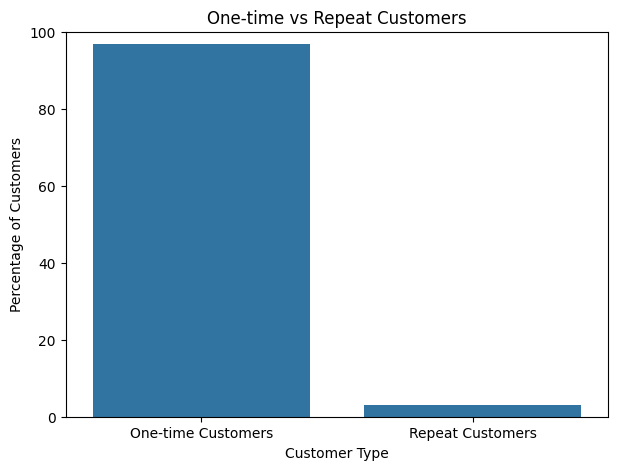

In [34]:
# Plot one-time and repeat customers

plt.figure(figsize=(7, 5))

sns.barplot(
    data=pd.DataFrame({
        'Customer Type': ['One-time Customers', 'Repeat Customers'],
        'Percentage': [
            one_time_customers / total_customers * 100,
            repeat_customers / total_customers * 100
        ]
    }),
    x='Customer Type',
    y='Percentage'
)

plt.title('One-time vs Repeat Customers')
plt.ylabel('Percentage of Customers')
plt.xlabel('Customer Type')
plt.ylim(0, 100)
plt.show()

### Chart 2: Top 10 Product Categories by Sales

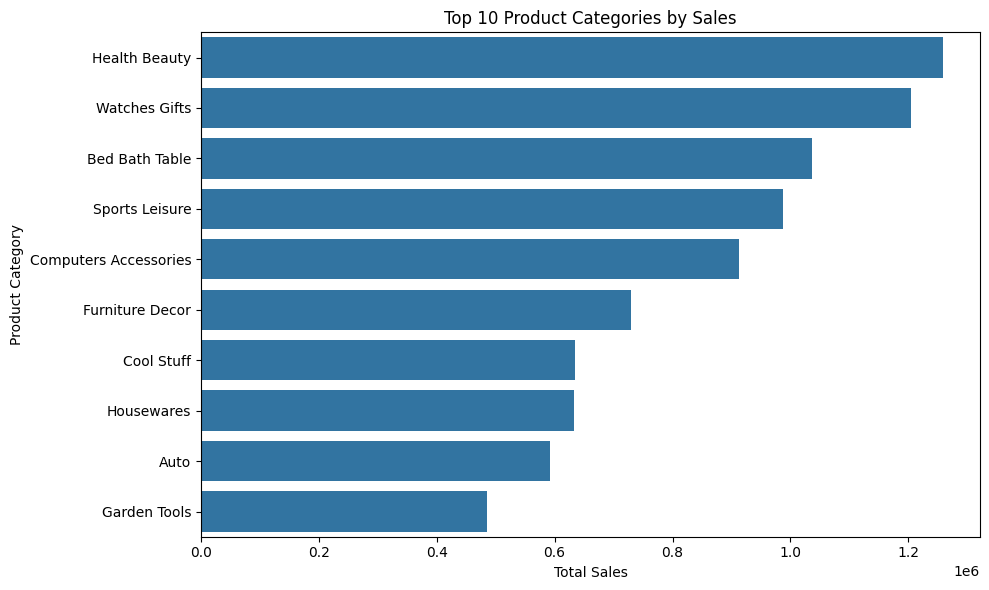

In [42]:
# Plot the top 10 product categories by sales
plt.figure(figsize=(10, 6))

sns.barplot(
    x=category_sales.head(10).values,
    y=category_sales.head(10).index
)

plt.title('Top 10 Product Categories by Sales')
plt.xlabel('Total Sales')
plt.ylabel('Product Category')
plt.tight_layout()
plt.show()

### Chart 3: Delivery Time Distribution

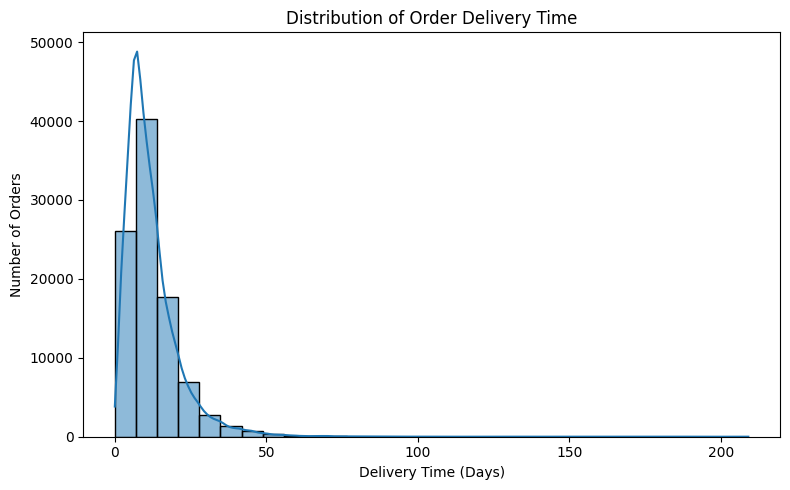

In [36]:
# Plot the distribution of delivery times
plt.figure(figsize=(8, 5))

sns.histplot(
    data=delivered_orders,
    x='delivery_days',
    bins=30,
    kde=True
)

plt.title('Distribution of Order Delivery Time')
plt.xlabel('Delivery Time (Days)')
plt.ylabel('Number of Orders')
plt.tight_layout()
plt.show()

### Chart 4: Customer Review Scores

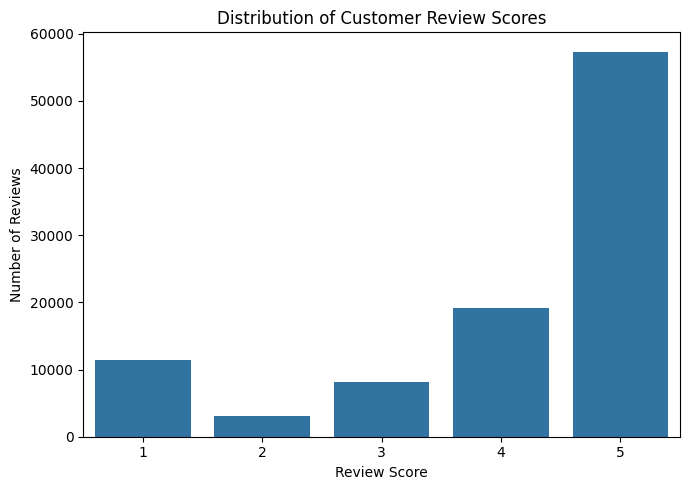

In [37]:
# Plot the distribution of customer review scores
plt.figure(figsize=(7, 5))

sns.countplot(
    data=order_reviews,
    x='review_score'
)

plt.title('Distribution of Customer Review Scores')
plt.xlabel('Review Score')
plt.ylabel('Number of Reviews')
plt.tight_layout()
plt.show()

### Chart 5: Monthly Sales Trends

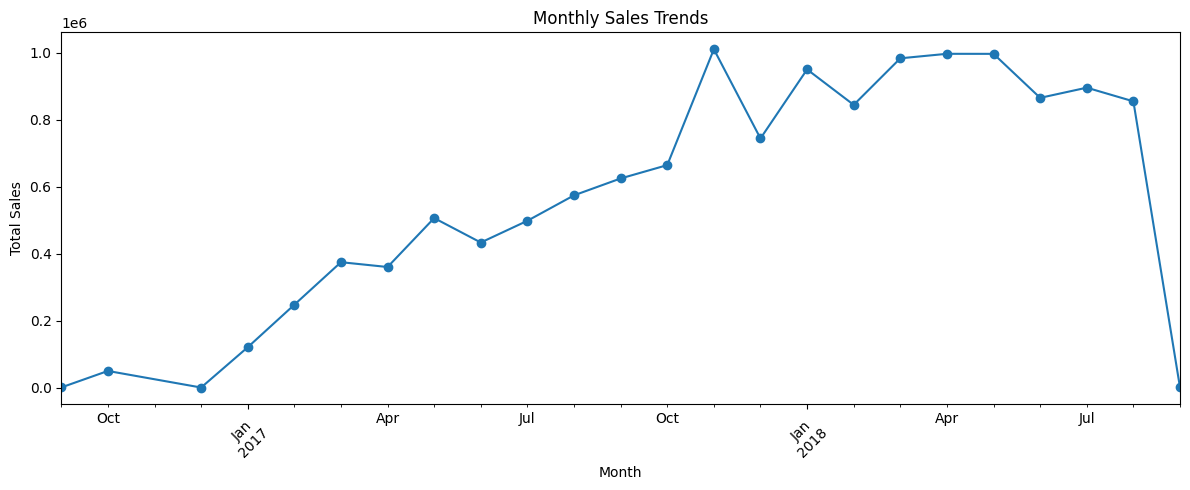

In [38]:
# Plot monthly sales trends
plt.figure(figsize=(12, 5))

monthly_sales.plot(kind='line', marker='o')

plt.title('Monthly Sales Trends')
plt.xlabel('Month')
plt.ylabel('Total Sales')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## 11) Business Insights and Conclusions



### Key Findings

1. **Customer Retention:** 96.88% of customers placed only one order, while just 3.12% made repeat purchases. This suggests that customer retention is a potential area for improvement.

2. **Product Categories:** Health and Beauty generated the highest sales, followed by Watches and Gifts and Bed Bath Table.

3. **Delivery Performance:** The average delivery time was approximately 12 days, with a median of 10 days. Most orders were delivered within 15 days, although some experienced significant delays.

4. **Customer Reviews:** 57.78% of reviews received 5 stars, indicating generally positive customer experiences. However, 14.69% received 1 or 2 stars.

5. **Sales Trends:** Monthly sales generally increased throughout 2017 and remained strong during most of 2018. November 2017 recorded the highest monthly sales in the period examined.

###  Conclusion

The analysis of the Olist e-commerce dataset revealed several patterns in customer behaviour, product sales, delivery performance, and customer satisfaction.

While the platform recorded generally positive customer reviews and strong sales, its repeat-purchase rate was relatively low. Improving customer retention and addressing delivery delays could be useful areas of focus for the business.

This project provided practical experience in data cleaning, SQL queries, data analysis using Pandas, and data visualization.